# PROJET FINAL : Optimisation du déploiement d'une infrastructure de
# Captage, Transport et Stockage du CO$_2$ (CCTS)

## Introduction

L'objectif est d'optimiser, sur un horizon de $T = 25$ ans, le déploiement d'une chaîne CCTS : décider chaque année
1) sur quels sites installer la technologie de captage (qui capte 90 % des émissions du site), 2) quelle quantité de CO$_2$
transporter sur chaque connexion et avec quelle technologie (camion, rail, pipeline), afin de respecter une trajectoire
de réduction linéaire des émissions à coût minimal.

On résout ici l'instance `CCTS-instance_medium.txt`.

## Formulation du problème

### Ensembles
 $\mathcal{N} = \mathcal{N}_S \cup \mathcal{N}_C \cup \mathcal{N}_T$ = ensemble des noeuds (sites de stockage, sites de captage, hubs de transport) <br />
 $\mathcal{L} = \{truck, rail, pipe\}$ = technologies de transport <br />
 $\mathcal{A} = \{(i,j) \in \mathcal{N}^2,\ i \neq j\}$ = arcs orientés ($F_{ij}$ : flux de $i$ vers $j$) <br />
 $\mathcal{T} = \{0, \dots, T-1\}$ = années de l'horizon

### Paramètres
 $E_i$ = émissions annuelles du site $i \in \mathcal{N}_C$ sans captage <br />
 $t^{avail}_s$ = première année où le site de stockage $s \in \mathcal{N}_S$ est disponible <br />
 $L_{ij}$ = distance euclidienne entre $i$ et $j$, calculée à partir des coordonnées $(x_i, y_i)$ <br />
 $w^{rail}_{ij} \in \{0,1\}$ = 1 si une ligne ferroviaire existe entre $i$ et $j$ <br />
 $\beta_{1,l}, \beta_{2,l}$ = coefficients de coût opératoire de la technologie $l$ <br />
 $\gamma_l$ = coefficient d'émissions de la technologie $l$ <br />
 $\alpha_1, \alpha_2$ = coefficients du coût d'investissement annualisé des pipelines <br />
 $Q_{init} = \sum_{i \in \mathcal{N}_C} E_i$, $Q_T$ = émissions annuelles initiales et cibles <br />
 $a = \dfrac{Q_T - Q_{init}}{T} < 0$ = pente de la trajectoire de réduction linéaire <br />
 $M$ = grand nombre (ici $M = 0.9 \sum_i E_i$, flux maximal possible sur le réseau)

### Variables
 $CC_i(t) \in \{0,1\}$ = 1 si le captage est installé sur le site $i$ à l'année $t$ <br />
 $F^l_{ij}(t) \geq 0$ = flux de CO$_2$ transporté de $i$ vers $j$ avec la technologie $l$ à l'année $t$ <br />
 $P_{ij}(t) \geq 0$ = capacité $S_{ij}$ du pipeline installé entre $i$ et $j$ (0 si pas de pipeline) <br />
 $p_{ij}(t) \in \{0,1\}$ = 1 si un pipeline existe entre $i$ et $j$ à l'année $t$

### Objectif
Minimiser le coût total sur l'horizon : <br />
$\min C_{tot} = \sum_{t \in \mathcal{T}} \left[ \sum_{l} \sum_{(i,j)} \left( \beta_{1,l} F^l_{ij}(t) L_{ij} + \beta_{2,l} F^l_{ij}(t) \right) + \sum_{(i,j)} \left( \alpha_1 P_{ij}(t) + \alpha_2 L_{ij}\, p_{ij}(t) \right) \right]$

### Contraintes
Émissions sous la trajectoire linéaire, $\forall t$ : <br />
 $E_{tot}(t) = \sum_{i \in \mathcal{N}_C} \left( E_i (1 - CC_i(t)) + 0.1\, E_i\, CC_i(t) \right) + \sum_l \sum_{(i,j)} \gamma_l F^l_{ij}(t) L_{ij} \leq Q_{init} + a\, t$

Conservation des flux aux hubs, $\forall j \in \mathcal{N}_T, \forall t$ : <br />
 $\sum_l \sum_i F^l_{ij}(t) = \sum_l \sum_k F^l_{jk}(t)$

Évacuation du CO$_2$ capté, $\forall i \in \mathcal{N}_C, \forall t$ : un site de captage peut aussi servir de point de
passage, la conservation des flux s'y applique avec un terme source égal au CO$_2$ capté (si $CC_i(t) = 0$, c'est un
simple noeud de transit : entrée = sortie) <br />
 $\sum_l \sum_j F^l_{ij}(t) - \sum_l \sum_j F^l_{ji}(t) = 0.9\, E_i\, CC_i(t)$

Les sites de stockage sont des puits : pas de conservation des flux, ils absorbent tout ce qui arrive (capacité
illimitée), mais rien n'en repart, $\forall s \in \mathcal{N}_S, \forall t$ : <br />
 $\sum_l \sum_j F^l_{sj}(t) = 0$

Un site de stockage ne reçoit rien avant sa date de disponibilité, $\forall s \in \mathcal{N}_S, \forall t < t^{avail}_s$ : <br />
 $\sum_l \sum_i F^l_{is}(t) = 0$

Irréversibilité du captage, $\forall i, \forall t \geq 1$ : <br />
 $CC_i(t) \geq CC_i(t-1)$

Rail disponible seulement si une ligne existe (sans limite de capacité sinon), $\forall (i,j), \forall t$ : <br />
 $F^{rail}_{ij}(t) \leq M\, w^{rail}_{ij}$

Flux pipeline limité par la capacité installée, $\forall (i,j), \forall t$ : <br />
 $F^{pipe}_{ij}(t) \leq P_{ij}(t)$, $\quad P_{ij}(t) \leq M\, p_{ij}(t)$

Capacité du pipeline figée après construction (si $P_{ij}(t) \neq 0$ alors $P_{ij}(t+1) = P_{ij}(t)$), linéarisée avec $p_{ij}$, $\forall (i,j), \forall t < T-1$ : <br />
 $p_{ij}(t+1) \geq p_{ij}(t)$ <br />
 $P_{ij}(t+1) - P_{ij}(t) \leq M (1 - p_{ij}(t))$ <br />
 $P_{ij}(t) - P_{ij}(t+1) \leq M (1 - p_{ij}(t))$

## Configuration du run

**À régler ici avant de lancer, puis faire « Restart » et « Run All ».**

- `INSTANCE` : `'small'`, `'medium'` ou `'large'`.
- `RUN_SOLVER = True` : résout avec Gurobi puis enregistre la solution dans `solution_<instance>.json`.
- `RUN_SOLVER = False` : ne résout pas et charge ce fichier (après un `git pull`, si quelqu'un l'a déjà calculé).
- `TIME_LIMIT` et `MIP_GAP` : Gurobi s'arrête à la première de ces deux limites et garde la meilleure solution trouvée.

In [25]:
INSTANCE = 'large'
RUN_SOLVER = True
TIME_LIMIT = 3600   # secondes
MIP_GAP = 0.01      # s'arrête à 1 % de l'optimum

INSTANCE_FILES = {
    'small': 'CCTS_instance_small.txt',
    'medium': 'CCTS-instance_medium.txt',
    'large': 'CCTS-instance_large.txt',
}
SOLUTION_FILE = f'solution_{INSTANCE}.json'

## Lecture de l'instance

Le fichier d'instance est lu ligne par ligne : les lignes `nom = valeur` donnent les scalaires, les autres lignes non
commentées donnent, dans l'ordre, les sites de stockage, les sites de captage, les hubs puis la matrice $w^{rail}$.
C'est cet ordre qui distingue les trois sous-ensembles de noeuds $\mathcal{N}_S$, $\mathcal{N}_C$ et $\mathcal{N}_T$.
Les trois blocs `beta_1, beta_2, gamma` correspondent dans l'ordre au camion, au rail et au pipeline.

Remarque : dans `CCTS-instance_medium.txt`, l'en-tête indique `n_capture = 5` alors que 9 sites de captage sont listés
($N = 11 = 2 + 9$). Le nombre de sites de captage est donc déduit de $N$ : $n_C = N - n_S - n_T$.

In [26]:
import math
%load_ext autoreload
%autoreload 2

def read_instance(path):
    scalars = []   # (nom, valeur) dans l'ordre du fichier
    rows = []      # lignes de données numériques
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line or line.startswith('#'):
                continue
            if '=' in line:
                name, val = line.split('=')
                scalars.append((name.strip(), float(val)))
            else:
                rows.append([float(x) for x in line.split(',')])

    sc = dict(scalars[:5])   # T, N, n_storage, n_capture, n_hubs
    T, N = int(sc['T']), int(sc['N'])
    n_s, n_h = int(sc['n_storage']), int(sc['n_hubs'])
    n_c = N - n_s - n_h   # l'en-tête n_capture n'est pas toujours cohérent avec N
    if n_c != int(sc['n_capture']):
        print(f"Attention : n_capture = {int(sc['n_capture'])} dans le fichier, {n_c} sites de captage lus")

    data = {'T': T, 'N': N}
    data['storage'] = {int(r[0]): (r[1], r[2]) for r in rows[:n_s]}
    data['avail'] = {int(r[0]): int(r[3]) if len(r) > 3 else 0 for r in rows[:n_s]}
    data['capture'] = {int(r[0]): (r[1], r[2]) for r in rows[n_s:n_s+n_c]}
    data['E'] = {int(r[0]): r[3] for r in rows[n_s:n_s+n_c]}
    data['hubs'] = {int(r[0]): (r[1], r[2]) for r in rows[n_s+n_c:n_s+n_c+n_h]}
    w = rows[n_s+n_c+n_h:n_s+n_c+n_h+N]
    data['w_rail'] = {(i, j): int(w[i][j]) for i in range(N) for j in range(N)}

    techno = ['truck', 'rail', 'pipe']
    params = scalars[5:]
    data['beta_1'] = {l: params[3*k][1] for k, l in enumerate(techno)}
    data['beta_2'] = {l: params[3*k+1][1] for k, l in enumerate(techno)}
    data['gamma'] = {l: params[3*k+2][1] for k, l in enumerate(techno)}
    data['alpha_1'] = dict(params)['alpha_1']
    data['alpha_2'] = dict(params)['alpha_2']

    coords = {**data['storage'], **data['capture'], **data['hubs']}
    data['coords'] = coords
    data['L'] = {(i, j): math.dist(coords[i], coords[j]) for i in coords for j in coords}
    return data

data = read_instance(INSTANCE_FILES[INSTANCE])
data

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


{'T': 25,
 'N': 18,
 'storage': {0: (0.0, 10.0), 7: (6.0, 4.0)},
 'avail': {0: 0, 7: 14},
 'capture': {1: (9.0, 10.0),
  2: (5.0, 7.0),
  3: (10.0, 4.0),
  4: (5.0, 2.0),
  5: (0.0, 0.0),
  6: (4.5, 1.0),
  8: (8.5, 0.0),
  9: (2.0, 6.0),
  10: (7.0, 8.0),
  12: (4.0, 7.0),
  14: (3.0, 4.0),
  15: (6.0, 8.0),
  16: (2.0, 1.0),
  17: (3.0, 2.0)},
 'E': {1: 200.0,
  2: 250.0,
  3: 400.0,
  4: 200.0,
  5: 350.0,
  6: 50.0,
  8: 65.0,
  9: 90.0,
  10: 45.0,
  12: 320.0,
  14: 80.0,
  15: 150.0,
  16: 60.0,
  17: 80.0},
 'hubs': {11: (1.0, 10.0), 13: (2.0, 2.0)},
 'w_rail': {(0, 0): 0,
  (0, 1): 0,
  (0, 2): 0,
  (0, 3): 0,
  (0, 4): 0,
  (0, 5): 0,
  (0, 6): 0,
  (0, 7): 0,
  (0, 8): 0,
  (0, 9): 0,
  (0, 10): 0,
  (0, 11): 0,
  (0, 12): 0,
  (0, 13): 0,
  (0, 14): 0,
  (0, 15): 0,
  (0, 16): 0,
  (0, 17): 0,
  (1, 0): 0,
  (1, 1): 0,
  (1, 2): 0,
  (1, 3): 0,
  (1, 4): 0,
  (1, 5): 0,
  (1, 6): 0,
  (1, 7): 0,
  (1, 8): 0,
  (1, 9): 0,
  (1, 10): 0,
  (1, 11): 0,
  (1, 12): 0,
  (1, 13): 

## Résolution avec PYOMO

### Création du modèle

In [27]:
# Import of the pyomo module
from pyomo.environ import *

# Creation of a Concrete Model
model = ConcreteModel()

### Définition des ensembles

In [28]:
## Define sets ##
#  Sets

model.NS = Set(initialize=sorted(data['storage']), doc='Storage sites')
model.NC = Set(initialize=sorted(data['capture']), doc='Capture sites')
model.NT = Set(initialize=sorted(data['hubs']), doc='Transport hubs')
model.N = Set(initialize=sorted(data['coords']), doc='All nodes')
model.A = Set(initialize=[(i, j) for i in model.N for j in model.N if i != j], doc='Directed arcs')
model.L = Set(initialize=['truck', 'rail', 'pipe'], doc='Transport technologies')
model.T = Set(initialize=range(data['T']), doc='Years t = 0..T-1')

### Paramètres

In [29]:
## Define parameters ##
#   Parameters

model.E = Param(model.NC, initialize=data['E'], doc='Yearly emissions of capture site i')
model.avail = Param(model.NS, initialize=data['avail'], doc='First year storage site s is available')
model.dist = Param(model.A, initialize={a: data['L'][a] for a in model.A}, doc='Distance between i and j')
model.w_rail = Param(model.A, initialize={a: data['w_rail'][a] for a in model.A}, doc='1 if a rail connection exists')
model.beta_1 = Param(model.L, initialize=data['beta_1'], doc='Operating cost per unit of flow and distance')
model.beta_2 = Param(model.L, initialize=data['beta_2'], doc='Operating cost per unit of flow')
model.gamma = Param(model.L, initialize=data['gamma'], doc='Transport emissions per unit of flow and distance')
model.alpha_1 = Param(initialize=data['alpha_1'], doc='Annualized pipeline cost per unit of capacity')
model.alpha_2 = Param(initialize=data['alpha_2'], doc='Annualized pipeline cost per unit of length')

model.Q_init = Param(initialize=sum(data['E'].values()), doc='Initial yearly emissions')
model.Q_T = Param(initialize=0.2 * model.Q_init, doc='Target yearly emissions')
model.a = Param(initialize=(model.Q_T - model.Q_init) / data['T'], doc='Slope of the linear reduction')
model.M = Param(initialize=0.9 * sum(data['E'].values()), doc='Big-M: maximum total captured flow')

### Variables

In [30]:
## Define variables ##
#  Variables

model.CC = Var(model.NC, model.T, domain=Binary, doc='1 if carbon capture installed at site i in year t')
model.F = Var(model.L, model.A, model.T, bounds=(0.0, None), doc='Flow of CO2 on arc (i,j) with techno l in year t')
model.P = Var(model.A, model.T, bounds=(0.0, None), doc='Capacity of the pipeline on arc (i,j) in year t')
model.p = Var(model.A, model.T, domain=Binary, doc='1 if a pipeline exists on arc (i,j) in year t')

### Contraintes

In [31]:
## Define constraints ##

def emissions_rule(model, t):
    E_sites = sum(model.E[i] * (1 - model.CC[i, t]) + 0.1 * model.E[i] * model.CC[i, t] for i in model.NC)
    E_transport = sum(model.gamma[l] * model.F[l, i, j, t] * model.dist[i, j] for l in model.L for (i, j) in model.A)
    return E_sites + E_transport <= model.Q_init + model.a * t
model.emissions = Constraint(model.T, rule=emissions_rule, doc='Emissions below the linear trajectory')

def outflow(model, i, t):
    return sum(model.F[l, i, j, t] for l in model.L for j in model.N if j != i)

def inflow(model, i, t):
    return sum(model.F[l, j, i, t] for l in model.L for j in model.N if j != i)

def hub_balance_rule(model, j, t):
    return inflow(model, j, t) == outflow(model, j, t)
model.hub_balance = Constraint(model.NT, model.T, rule=hub_balance_rule, doc='Flow conservation at hubs')

def capture_rule(model, i, t):
    return outflow(model, i, t) - inflow(model, i, t) == 0.9 * model.E[i] * model.CC[i, t]
model.capture = Constraint(model.NC, model.T, rule=capture_rule, doc='Captured CO2 must be evacuated (transit allowed)')

def storage_sink_rule(model, s, t):
    return outflow(model, s, t) == 0
model.storage_sink = Constraint(model.NS, model.T, rule=storage_sink_rule, doc='Nothing leaves a storage site')

def storage_avail_rule(model, s, t):
    if t >= model.avail[s]:
        return Constraint.Skip
    return inflow(model, s, t) == 0
model.storage_avail = Constraint(model.NS, model.T, rule=storage_avail_rule, doc='No inflow before availability date')

def cc_irreversible_rule(model, i, t):
    if t == 0:
        return Constraint.Skip
    return model.CC[i, t] >= model.CC[i, t-1]
model.cc_irreversible = Constraint(model.NC, model.T, rule=cc_irreversible_rule, doc='Carbon capture is irreversible')

def rail_rule(model, i, j, t):
    return model.F['rail', i, j, t] <= model.M * model.w_rail[i, j]
model.rail = Constraint(model.A, model.T, rule=rail_rule, doc='Rail only where a line exists')

def pipe_capacity_rule(model, i, j, t):
    return model.F['pipe', i, j, t] <= model.P[i, j, t]
model.pipe_capacity = Constraint(model.A, model.T, rule=pipe_capacity_rule, doc='Pipeline flow below capacity')

def pipe_exists_rule(model, i, j, t):
    return model.P[i, j, t] <= model.M * model.p[i, j, t]
model.pipe_exists = Constraint(model.A, model.T, rule=pipe_exists_rule, doc='Capacity only if pipeline built')

def pipe_keep_rule(model, i, j, t):
    if t == data['T'] - 1:
        return Constraint.Skip
    return model.p[i, j, t+1] >= model.p[i, j, t]
model.pipe_keep = Constraint(model.A, model.T, rule=pipe_keep_rule, doc='A built pipeline stays in service')

def pipe_frozen_up_rule(model, i, j, t):
    if t == data['T'] - 1:
        return Constraint.Skip
    return model.P[i, j, t+1] - model.P[i, j, t] <= model.M * (1 - model.p[i, j, t])
model.pipe_frozen_up = Constraint(model.A, model.T, rule=pipe_frozen_up_rule, doc='Capacity cannot increase after construction')

def pipe_frozen_down_rule(model, i, j, t):
    if t == data['T'] - 1:
        return Constraint.Skip
    return model.P[i, j, t] - model.P[i, j, t+1] <= model.M * (1 - model.p[i, j, t])
model.pipe_frozen_down = Constraint(model.A, model.T, rule=pipe_frozen_down_rule, doc='Capacity cannot decrease after construction')

### Objectif et résolution

In [32]:
## Define Objective ##

def cost_t(model, t):
    operating = sum(model.beta_1[l] * model.F[l, i, j, t] * model.dist[i, j] + model.beta_2[l] * model.F[l, i, j, t]
                    for l in model.L for (i, j) in model.A)
    investment = sum(model.alpha_1 * model.P[i, j, t] + model.alpha_2 * model.dist[i, j] * model.p[i, j, t]
                     for (i, j) in model.A)
    return operating + investment

def objective_rule(model):
    return sum(cost_t(model, t) for t in model.T)
model.objective = Objective(rule=objective_rule, sense=minimize, doc='Total cost over the horizon')

### Récupération des résultats

`pyomo_postprocess()` affiche le plan de déploiement : l'année d'installation du captage sur chaque site, les pipelines
construits avec leur capacité, et les flux non nuls par technologie.

In [33]:
## Display of the output ##

def pyomo_postprocess(options=None, instance=None, results=None):
    print("Coût total :", value(model.objective))

    print("\nInstallation du captage (première année où CC_i = 1) :")
    for i in model.NC:
        years = [t for t in model.T if value(model.CC[i, t]) > 0.5]
        print(f"  site {i} : {'année ' + str(years[0]) if years else 'jamais'}")

    print("\nPipelines construits :")
    for (i, j) in model.A:
        years = [t for t in model.T if value(model.p[i, j, t]) > 0.5]
        if years:
            print(f"  {i} -> {j} : construit en année {years[0]}, capacité S = {value(model.P[i, j, years[0]]):.2f}")

    print("\nFlux non nuls (l, i -> j : flux par année) :")
    for l in model.L:
        for (i, j) in model.A:
            flows = [round(value(model.F[l, i, j, t]), 2) for t in model.T]
            if any(f > 1e-6 for f in flows):
                print(f"  {l}, {i} -> {j} : {flows}")

    print("\nCO2 reçu par les sites de stockage (par année) :")
    for s in model.NS:
        print(f"  site {s} (disponible en t = {model.avail[s]}) : {[round(value(inflow(model, s, t)), 2) for t in model.T]}")

    print("\nÉmissions annuelles vs trajectoire :")
    for t in model.T:
        print(f"  t = {t:2d} : E_tot = {value(model.emissions[t].body):8.2f} <= {value(model.Q_init + model.a * t):8.2f}")

### Enregistrement et chargement de la solution

Rien à modifier ici : ces fonctions permettent de partager une solution sans relancer le solveur. Le fichier JSON
ne vaut que pour la même instance et le même modèle : si un paramètre ou une contrainte change, il faut résoudre à nouveau.

In [34]:
import json

def save_solution(model, path, instance, results=None):
    sol = {'instance': instance, 'objective': value(model.objective), 'variables': {}}
    if results is not None:
        sol['lower_bound'] = results.problem.lower_bound
        sol['termination'] = str(results.solver.termination_condition)
    for var in model.component_objects(Var):
        sol['variables'][var.name] = [[*idx, var[idx].value] for idx in var if var[idx].value]
    with open(path, 'w') as f:
        json.dump(sol, f)

def load_solution(model, path):
    with open(path) as f:
        sol = json.load(f)
    for var in model.component_objects(Var):
        for idx in var:
            var[idx].set_value(0, skip_validation=True)
        for *idx, val in sol['variables'][var.name]:
            var[tuple(idx)].set_value(val, skip_validation=True)
    return sol

### Résolution ou chargement

Rien à modifier ici : tout se règle dans « Configuration du run ». Si `RUN_SOLVER = True`, cette cellule peut durer
jusqu'à `TIME_LIMIT` : laisser le PC allumé. Un `WARNING` sur un statut « aborted » est normal quand la limite de
temps est atteinte. Vérifier ensuite le gap dans le journal Gurobi.

In [35]:
# This emulates what the pyomo command-line tools does
from pyomo.opt import SolverFactory
if RUN_SOLVER:
    opt = SolverFactory("gurobi")
    opt.options["TimeLimit"] = TIME_LIMIT
    opt.options["MIPGap"] = MIP_GAP
    results = opt.solve(model, tee=True)
    #sends results to stdout
    results.write()
    save_solution(model, SOLUTION_FILE, INSTANCE, results)
    print("Solution enregistrée dans", SOLUTION_FILE)
else:
    results = None
    sol = load_solution(model, SOLUTION_FILE)
    print("Solution chargée depuis", SOLUTION_FILE, ":", sol['termination'], "- borne inférieure", sol['lower_bound'])
print("\nDisplaying Solution\n" + '-'*60)
pyomo_postprocess(None, model, results)

Read LP format model from file C:\Users\ARTHUR~1\AppData\Local\Temp\tmp4ihgb27l.pyomo.lp
Reading time = 0.21 seconds
x1: 45807 rows, 38600 columns, 157738 nonzeros
Set parameter TimeLimit to value 3600
Set parameter MIPGap to value 0.01
Gurobi Optimizer version 13.0.3 build v13.0.3rc0 (win64 - Windows 11+.0 (26200.2))

CPU model: AMD Ryzen 5 5600H with Radeon Graphics, instruction set [SSE2|AVX|AVX2]
Thread count: 6 physical cores, 12 logical processors, using up to 12 threads

Non-default parameters:
TimeLimit  3600
MIPGap  0.01

Optimize a model with 45807 rows, 38600 columns and 157738 nonzeros (Min)
Model fingerprint: 0x1b458801
Model has 38250 linear objective coefficients
Variable types: 30600 continuous, 8000 integer (8000 binary)
Coefficient statistics:
  Matrix range     [1e-04, 2e+03]
  Objective range  [5e-04, 4e+04]
  Bounds range     [1e+00, 1e+00]
  RHS range        [7e+01, 2e+03]

Presolve removed 12984 rows and 11974 columns
Presolve time: 0.68s
Presolved: 32823 rows, 2

### Vérification et figures

Rien à modifier ici : l'audit et les figures portent sur la solution résolue ou chargée. Les images sont enregistrées
dans `figures/` avec le nom de l'instance.


 AUDIT INDÉPENDANT DES CONTRAINTES DE LA SOLUTION (Hint 2)
 Contrainte vérifiée                                        | Écart Max  | Statut
------------------------------------------------------------------------------
 1. Évacuation CO2 captage (outflow - inflow = 0.9*E*CC)    | 0.00e+00   | [OK] PASS
 2. Bilan de flux aux hubs (inflow = outflow)               | 0.00e+00   | [OK] PASS
 3. Sites de stockage : aucune sortie (outflow = 0)         | 0.00e+00   | [OK] PASS
 4. Stockage indisponible : aucune entrée avant t_avail     | 0.00e+00   | [OK] PASS
 5. Lignes de train : flux nul si ligne absente (w_rail = 0) | 0.00e+00   | [OK] PASS
 6. Capacité pipeline : flux pipe <= P_ij(t)                | 0.00e+00   | [OK] PASS
 7. Cohérence pipeline : capacité = 0 si non construit (p_ij=0) | 0.00e+00   | [OK] PASS
 8. Maintien des pipelines : p_ij(t+1) >= p_ij(t)           | 0.00e+00   | [OK] PASS
 9. Capacité pipeline figée : P_ij(t+1) == P_ij(t) une fois construit | 0.00e+00   | [OK] PASS

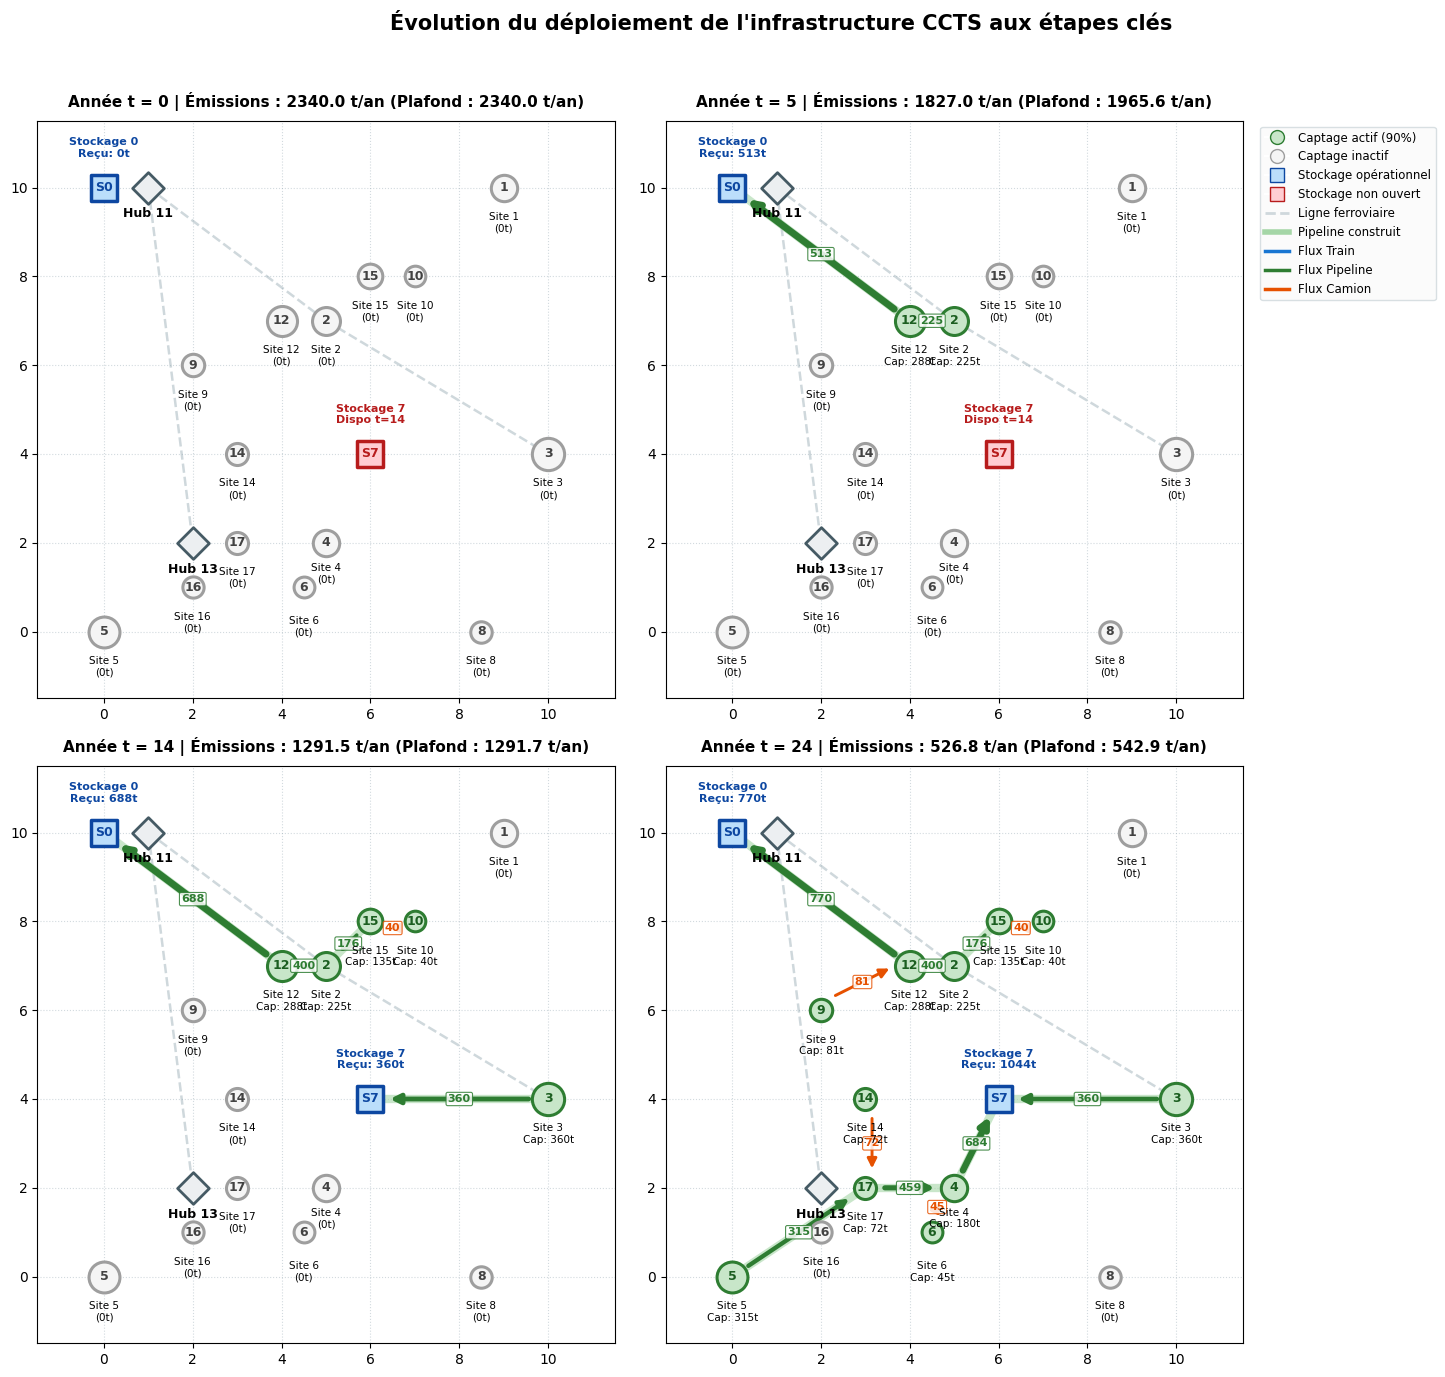

[OK] Dashboard de synthèse enregistré sous : figures/summary_large.png


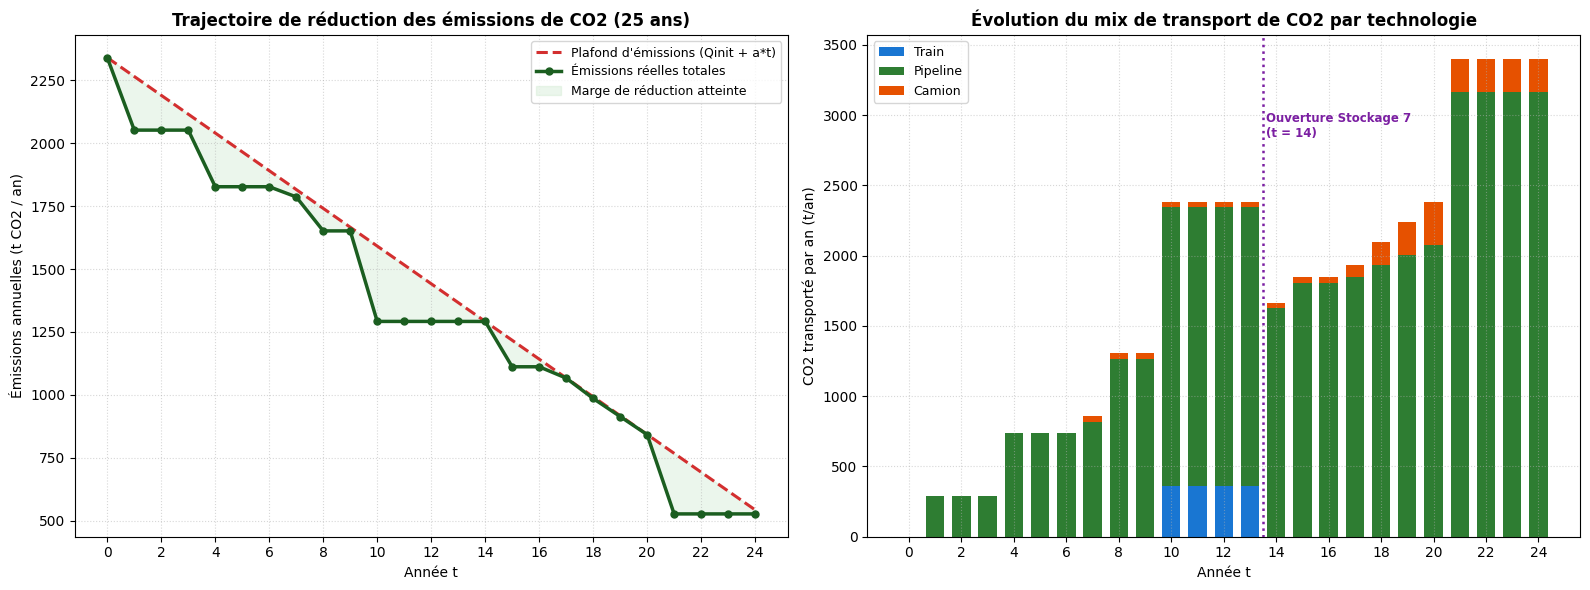

[OK] Fichier HTML interactif sauvegardé sous : figures/reseau_interactif_large.html


In [36]:
import importlib
import solution_visualizer as sv
importlib.reload(sv)

# 1. Audit formel des contraintes (Hint 2)
audit = sv.verify_constraints(data, model)

# 2. Planche 2x2 des jalons pour le rapport LaTeX
sv.plot_milestones(data, model, years=[0, 5, 14, 24], save_path=f'figures/milestones_{INSTANCE}.png')

# 3. Dashboard d'émissions et de mix modal sur 25 ans
sv.plot_summary_dashboard(data, model, save_path=f'figures/summary_{INSTANCE}.png')


# 4. Génère la figure interactive avec Slider et bouton Play/Pause
fig = sv.plot_interactive_plotly(data, model, save_html=f'figures/reseau_interactif_{INSTANCE}.html')